## 1. Import libraries and config

In [1]:
#there are a bunch of libraries used for computer vision
    #torchvision, torchvision.dataset, torchviison.models, torchvision.transfroms, torch.util.data.dataset and more

import torch
import torch.nn as nn

#import torchvision
import torchvision     
from torchvision import datasets   #for example dataset
from torchvision.transforms import ToTensor   #transform image to tensors

#for visualization
import matplotlib.pyplot as plt

**Color Configration**

In [82]:
# Define color codes
GREEN = '\033[92m'
BLUE = '\033[94m'
CYAN = '\033[96m'
BOLD = '\033[1m'
RED = '\033[31m'
END = '\033[0m' # Always use this to reset color

Loading a bunch of image dataset from pyTorch library `FashinMNIST` dataset.
1. *train_image* have features and also label/targets
2. *test_image* also have in similar manner.

In [2]:
#download the train and test dataset from FashinMNIST
train_image = datasets.FashionMNIST(     #that is full dataset which have features and target part 
    root = "data",
    train = True,
    download = True,
    transform = ToTensor()
)
test_image = datasets.FashionMNIST(        #this is also similar but differe in size
    root = "data",   
    train = False,
    download = True,
    transform = ToTensor()
)

In [3]:
image , label = train_image[0]
display(image.shape, label)          #return the shape of the image(in pixle color channel, hight and with) and the output of the prediction

torch.Size([1, 28, 28])

9

In [4]:
class_name = train_image.classes    
print(f"Training image size: {len(train_image)} \nTest image: {len(test_image)} \nThe class name: {class_name}")

Training image size: 60000 
Test image: 10000 
The class name: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


Visualize the image

Image size: torch.Size([1, 28, 28])
Image size: torch.Size([1, 28, 28])


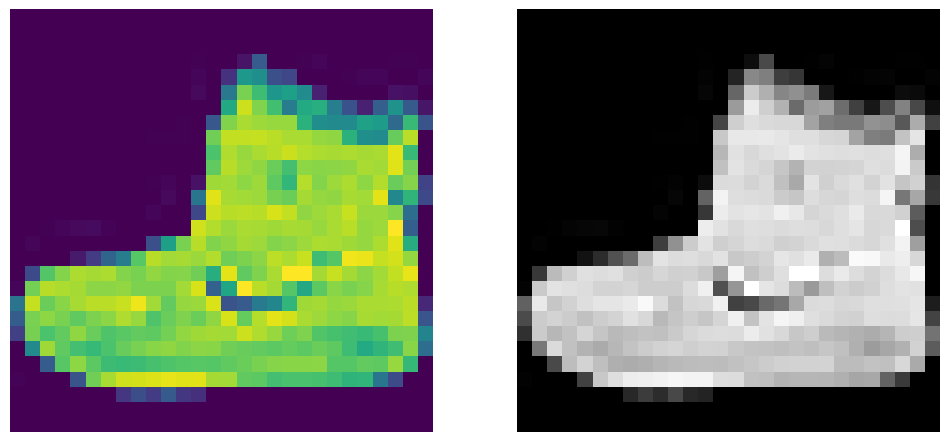

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

In [5]:
def show_image(axis, image, color=None):
    print(f"Image size: {image.shape}")
    plt.figure(figsize=(12, 6))
    if color=="gray":
        axis.imshow(image.squeeze(), cmap="gray")
    else:
        axis.imshow(image.squeeze())
    axis.axis("off")
fig, axis = plt.subplots(1, 2, sharey=True, figsize=(12, 6))   #two spaces
colored, gray = axis

show_image(colored, image=image, color=None)
show_image(gray, image=image, color="gray")
plt.show()

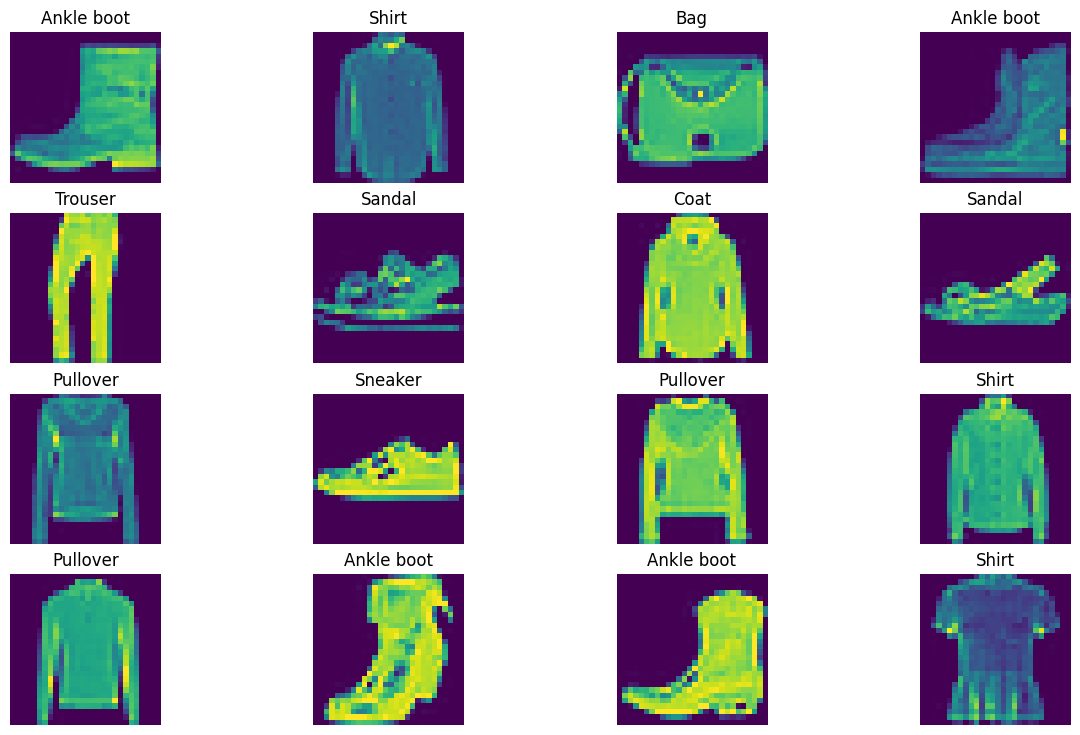

In [7]:
# Plot more images
torch.manual_seed(42)
fig = plt.figure(figsize=(15, 9))
rows, cols = 4, 4
for i in range(1, rows * cols + 1):
    random_idx = torch.randint(0, len(train_image), size=[1]).item()
    img, label = train_image[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze())
    plt.title(class_name[label])
    plt.axis(False);

In [8]:
#data loader
from torch.utils.data import DataLoader
BATCH_size = 32
train_dataloader = DataLoader(
    train_image,
    batch_size = BATCH_size,
    shuffle = True        #shuffle for train data is true and for test data is false because we want to keep the order of the test data
)

test_dataloader = DataLoader(
    test_image,
    batch_size = BATCH_size,
    shuffle = False
)

In [10]:
print(f"Train dataloader: {train_dataloader}, \nTest dataloader: {test_dataloader}")
print(len(train_dataloader), len(test_dataloader))   #return the number of batches in the train and test dataloader

Train dataloader: <torch.utils.data.dataloader.DataLoader object at 0x7d9328904350>, 
Test dataloader: <torch.utils.data.dataloader.DataLoader object at 0x7d9326d752e0>
1875 313


In [9]:
# Check out what's inside the training dataloader
train_features_batch, train_labels_batch = next(iter(train_dataloader))
test_features_batch, test_label_batch = next(iter(test_dataloader))
train_features_batch.shape, train_labels_batch.shape, test_features_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]), torch.Size([32, 1, 28, 28]))

Image size: torch.Size([1, 28, 28])
Label: 6, label size: torch.Size([])


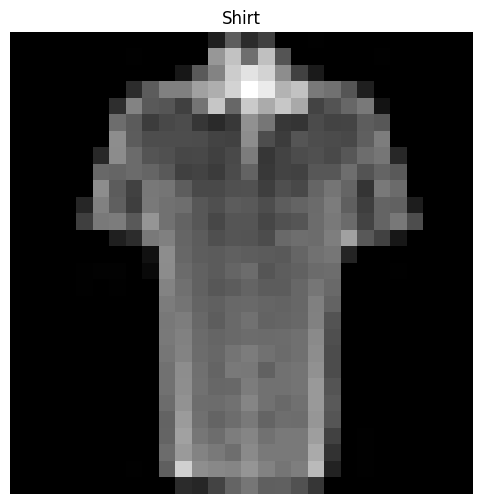

In [12]:
# Show a sample
torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.figure(figsize=(15, 6))
plt.imshow(img.squeeze(), cmap="gray")
plt.title(class_name[label])
plt.axis("Off");
print(f"Image size: {img.shape}")
print(f"Label: {label}, label size: {label.shape}")

## 2. Build Baseline Model

In [13]:
#flatten model
flatten_model = nn.Flatten()   #it flatten the the image of the model
image = train_features_batch[0]
flattened_image = flatten_model(image)

print(f"Original image shape: {image.shape} -> Flattened image shape: {flattened_image.shape}")

Original image shape: torch.Size([1, 28, 28]) -> Flattened image shape: torch.Size([1, 784])


In [14]:
#flatten nn.Flatten() layer are change the image from (channel, height, width) to (channel, height*width) one feature vector.

print(image.shape), print(flattened_image.shape), print(type(flattened_image))

torch.Size([1, 28, 28])
torch.Size([1, 784])
<class 'torch.Tensor'>


(None, None, None)

In [30]:
#now define the model in subclass 

class FashionModel0(nn.Module):
    def __init__(self, input_shape:int, hidden_layre:int, output_shape:int):
        super().__init__()
        self.layer_stack= nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape, out_features=hidden_layre), 
            nn.Linear(in_features=hidden_layre, out_features=output_shape)
        )
    def forward(self, x):
        return self.layer_stack(x)

star_layer = flattened_image.shape[1]
hidden_layer = 10
out_layer = len(class_name)

#initialize the model
model_0 = FashionModel0(input_shape=star_layer,
                        hidden_layre=hidden_layer,
                        output_shape=out_layer)

In [16]:
model_0

FashionModel0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

### **3. Loss, Optimizer and Evaluation**

In [17]:
import requests
from pathlib import Path 

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

helper_functions.py already exists, skipping download


In [18]:
# Import accuracy metric
from helper_functions import accuracy_fn # Note: could also use torchmetrics.Accuracy(task = 'multiclass', num_classes=len(class_names)).to(device)

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()        # this is also called "criterion"/"cost function" in some places
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)

In [19]:
from timeit import default_timer as Timer
def train_time_calculator(
        start:float, 
        end:float,
        device: torch.device=None):
    """this function is to calculate the total time for training the model on 
    cpu and gpu device and it is help full"""
    total_time = end - start
    print(f"Train time on {device} is: {total_time:.3f} second")
    return total_time
    

In [20]:
start_time = Timer()
a = 40*40
end_time = Timer()
train_time_calculator(start=start_time, end=end_time, device="CPU")

Train time on CPU is: 0.000 second


0.00010808100000758714

## 3. Creating Training Loop
The **workflow** i follow in this module are:
1. loop through epoch
2. loop through training batch, performing training steps, calculate the training loss per patches.
3. loop through testing batches and so on
4. print out what's happning 
5. time it all

In [21]:
from tqdm.auto import tqdm

#set the seed and start the timer
torch.manual_seed(42)
train_test_timer_start = Timer()

#Set the number of epoches(it should be small for now)
epoches = 3

for epoch in tqdm(range(epoches)):
    print(f"Epoch: {epoch}\n --------")
    train_loss = 0

    #add loop for training batches
    for batch, (x_train, y_train) in enumerate(train_dataloader):
        model_0.train()

        # 1. forward pass
        y_prediction = model_0(x_train)

        #2. calculate the loss
        loss = loss_fn(y_prediction,  y_train)
        train_loss += loss #comulate the loss for each batches

        #3. Optimizer zero grad
        optimizer.zero_grad()

        #4. loss backward pass
        loss.backward()

        #5. Optimizer steps
        optimizer.step()

        #Then look what is happning on the background
        if batch % 400 == 0:
            print(f"Looked at {batch * len(x_train)}/ {len(train_dataloader.dataset)} sampels")

    train_loss /= len(train_dataloader)  #average loss per batch

    ##for testing loop
    model_0.eval()  #to evaluation mode
    with torch.inference_mode():
        for x, y in test_dataloader:

            #1. forward pass
            test_prediction = model_0(x)

            #2. calculate the loss of test loop
            test_loss = loss_fn(test_prediction, y)

            #3. if there is accuracy calculate the accuracy of the model
            accuray = accuracy_fn(y_true=y, y_pred=test_prediction.argmax(dim=1))

    average_test_loss = test_loss / len(test_dataloader)

    print(f"\nTrain loss: {train_loss:.5f} | Test loss: {test_loss:.5f}, Test accuracy: {accuray:.2f}")

# Calculate training time      
train_time_end_on_cpu = Timer()
total_train_time_model_0 = train_time_calculator(start=train_test_timer_start, 
                                           end=train_time_end_on_cpu,
                                           device=str(next(model_0.parameters()).device))

/home/nigatie/Documents/ML_DL/Deep_Learning/.DL_VE/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
 --------
Looked at 0/ 60000 sampels
Looked at 12800/ 60000 sampels
Looked at 25600/ 60000 sampels
Looked at 38400/ 60000 sampels
Looked at 51200/ 60000 sampels


 33%|███▎      | 1/3 [00:08<00:16,  8.40s/it]


Train loss: 0.59484 | Test loss: 0.29358, Test accuracy: 93.75
Epoch: 1
 --------
Looked at 0/ 60000 sampels
Looked at 12800/ 60000 sampels
Looked at 25600/ 60000 sampels
Looked at 38400/ 60000 sampels
Looked at 51200/ 60000 sampels


 67%|██████▋   | 2/3 [00:18<00:09,  9.24s/it]


Train loss: 0.47946 | Test loss: 0.27532, Test accuracy: 93.75
Epoch: 2
 --------
Looked at 0/ 60000 sampels
Looked at 12800/ 60000 sampels
Looked at 25600/ 60000 sampels
Looked at 38400/ 60000 sampels
Looked at 51200/ 60000 sampels


100%|██████████| 3/3 [00:28<00:00,  9.37s/it]


Train loss: 0.45703 | Test loss: 0.32582, Test accuracy: 93.75
Train time on cpu is: 28.126 second


## 4. Make Predictions

In [22]:
import importlib
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import src.pyTorch as py

In [61]:
py = importlib.reload(py)   #reload the module 

#call the model 
model_1_result = py.model_eval(model=model_0, 
                      data_loader = test_dataloader, 
                      loss_fn = loss_fn, 
                      accuracy_fn = accuracy_fn)

model_1_result    #print the values in that model performance

{'model_name': 'FashionModel0',
 'model_loss': 2.3466436862945557,
 'model_acc': 9.994009584664537}

In [34]:
#device agnostice code to run the model on gpu if it is available otherwise run on cpu
device = "cuda" if torch.cuda.is_available() else "cpu"
device    

'cpu'

Since my pc have not gpu hardware(not suported) the defualt device is CPU.

## 5. Non linearity

3.1. Define the Model

In [56]:
#create model with non linear function(model definition using non linear function(ReLu))

class noneLinearModel(nn.Module):
    def __init__(self, input:int, hidden:int, output:int):
        super().__init__()
        self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input, out_features=hidden),
        nn.ReLU(),
        nn.Linear(in_features=hidden, out_features=output),
        nn.ReLU())
    def forward(self, x: torch.Tensor):
        return self.layer_stack(x)

In [57]:
#then assign the model and give the parameter

non_linear_model = noneLinearModel(
    input=star_layer,
    hidden=10, 
    output=len(class_name)
)

non_linear_model

noneLinearModel(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): ReLU()
    (3): Linear(in_features=10, out_features=10, bias=True)
    (4): ReLU()
  )
)

3.2 Define loss function and Optimizer

In [32]:
#loss function setup
non_lin_loss_fun = nn.CrossEntropyLoss()

#optimizer
non_lin_optimizer = torch.optim.SGD(params=non_linear_model.parameters(), lr=0.1)

3.3 Training and Testing loop

>I use custom function from other moduls

In [54]:
py = importlib.reload(py)
torch.manual_seed(42)

star_time = Timer()

epoches = 3
for epoch in tqdm(range(epoches)):
    print(f"Epoch: {epoch}\n --------")
    py.train_loop_fnc(non_linear_model, 
                    train_dataloader, 
                    non_lin_loss_fun, 
                    non_lin_optimizer, 
                    accuracy_fn, 
                    device)
    py.test_loop_fnc(non_linear_model,
                    test_dataloader,
                    non_lin_loss_fun,
                    accuracy_fn,
                    device)
end_time = Timer()
train_time_calculator(
    star_time, 
    end_time,
    device=device
)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
 --------
Train loss: 2.31975 | Train Accuracy: 10.03%



 33%|███▎      | 1/3 [00:16<00:33, 16.99s/it]

Test loss: 2.31998 | Test Accuracy: 10.02%
Epoch: 1
 --------
Train loss: 2.31975 | Train Accuracy: 10.03%



 67%|██████▋   | 2/3 [00:34<00:17, 17.02s/it]

Test loss: 2.31998 | Test Accuracy: 10.02%
Epoch: 2
 --------
Train loss: 2.31975 | Train Accuracy: 10.03%



100%|██████████| 3/3 [00:50<00:00, 17.00s/it]

Test loss: 2.31998 | Test Accuracy: 10.02%
Train time on cpu is: 50.994 second


50.9937562340001

Now evaluate our model using my previouse method.

In [59]:
py = importlib.reload(py)

non_linear_result = py.model_eval(
    non_linear_model,
    test_dataloader,
    non_lin_loss_fun,
    accuracy_fn
)

In [69]:
from pprint import pprint
%pprint

Pretty printing has been turned ON


In [85]:
print(f"{GREEN}{BOLD}The first Model result:{END}")
pprint(model_1_result)
print(f"\n{GREEN}{BOLD}Second Non linear model result:{END}")
pprint(non_linear_result)

The first Model result:
{'model_acc': 9.994009584664537,
 'model_loss': 2.3466436862945557,
 'model_name': 'FashionModel0'}

Second Non linear model result:
{'model_acc': 13.89776357827476,
 'model_loss': 2.3133962154388428,
 'model_name': 'noneLinearModel'}


As general the two models are worse than simply guessing, but non linear model are slightly better than model the other model

## 6. Building CNN